# Day 1 · 이론 4 추가 실습 — 특성 공학과 규제

교재 03-3 (`3-3.ipynb`)의 농어 데이터를 그대로 사용합니다. 이 노트북은 `3-3.ipynb`와 독립적으로 처음부터 실행할 수 있도록 데이터 준비·특성 확장·표준화 코드를 다시 포함합니다. 교재의 `3-3.ipynb`를 수정하지 않으며, 첫 셀부터 차례로 실행합니다. 결과는 scikit-learn·NumPy 버전에 따라 작은 소수점 차이가 있을 수 있습니다.

| 블록 | 내용 |
|---|---|
| 실습 A | 예측 오차와 규제 벌점 직접 계산하기 (데이터 없이 숫자 예제로 진행) |
| 실습 B | 규제 전후의 계수와 예측 성능 비교하기 |
| ⏩ 선택 확장 실습 | 라쏘의 alpha와 0인 계수 수 비교하기 |

## 0. 공통 준비 — 교재와 같은 농어 데이터, 5차 다항 특성, 표준화

이론 ④의 농어 56마리(길이·높이·두께), `random_state=42`, 훈련 42마리·테스트 14마리를 그대로 사용합니다. 교재와 같이 `degree=5`로 특성을 55개로 확장하고, 훈련 세트 기준으로 표준화한 `train_scaled`, `test_scaled`를 만듭니다.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# 농어의 길이·높이·두께
perch_full = pd.read_csv('https://bit.ly/perch_csv_data')

# 농어의 무게 (타깃)
perch_weight = np.array([
    5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0
])

train_input, test_input, train_target, test_target = train_test_split(
    perch_full, perch_weight, random_state=42
)

# 5차 다항 특성 (55개)
poly = PolynomialFeatures(degree=5, include_bias=False)
poly.fit(train_input)
train_poly = poly.transform(train_input)
test_poly = poly.transform(test_input)

# 훈련 세트 기준 표준화
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

print('훈련 입력:', train_scaled.shape, '| 테스트 입력:', test_scaled.shape)

훈련 입력: (42, 55) | 테스트 입력: (14, 55)


## 실습 A. 예측 오차와 규제 벌점 직접 계산하기

**실습 목표**: 간단한 숫자를 이용하여 규제를 적용하기 전과 후에 모델을 평가하는 기준이 어떻게 달라지는지 확인합니다. 이 실습은 규제의 계산 원리를 이해하기 위한 예제이며, 실제 농어 데이터로 학습한 모델의 계수는 사용하지 않습니다.

| 비교 항목 | 모델 A | 모델 B |
|---|---:|---:|
| 훈련 제곱오차 합 | 10 | 15 |
| 계수의 제곱합 | 100 | 9 |

규제가 없다면 훈련 오차가 더 작은 A가 선택됩니다. 계수의 제곱합을 사용하는 L2 벌점을 `alpha=0.1`로 적용하면 어떻게 달라지는지 계산합니다.

**규제된 학습 기준 = 훈련 제곱오차 합 + alpha × 계수의 제곱합**

In [9]:
alpha = 0.1

error_a = 10
error_b = 15

penalty_a = 100
penalty_b = 9

loss_a = error_a + alpha * penalty_a
loss_b = error_b + alpha * penalty_b

print(f'모델 A: {loss_a:.1f}')
print(f'모델 B: {loss_b:.1f}')

모델 A: 20.0
모델 B: 15.9


### 학생 응용 실습

위 셀의 `alpha`를 `0`, `0.01`, `0.1`, `1`로 변경하고 두 모델의 전체 학습 기준값을 비교해 보세요.

**실습 핵심**: 규제가 없는 모델은 훈련 데이터의 예측 오차를 줄이는 것에 집중하지만, 규제를 적용하면 계수 크기에 대한 벌점까지 함께 고려합니다. 따라서 훈련 오차가 조금 커지더라도 계수가 과도하게 커지는 것을 억제할 수 있습니다.

✅ **완료 확인**: `alpha=0.1`에서 모델 A `20.0`, 모델 B `15.9`가 출력됩니다. 응용 실습에서는 `alpha=0`과 `0.01`까지는 A(10.0, 11.0)가 작고, `alpha=0.1`부터 B(15.9, 24.0)가 작아져 선택이 뒤집히는 것을 확인합니다.

## 실습 B. 규제 전후의 계수와 예측 성능 비교하기

**실습 목표**: 같은 표준화 입력(`train_scaled`, `test_scaled`)을 사용하여 규제가 없는 선형 회귀, 릿지, 라쏘를 비교합니다.

1. 규제가 없는 선형 회귀와 릿지·라쏘의 계수를 비교합니다.
2. 동일한 데이터에서 규제 적용 전후의 예측 성능을 확인합니다.
3. 릿지와 라쏘에서 계수가 0이 되는 방식의 차이를 살펴봅니다.

### 1단계. 동일한 입력으로 세 모델 훈련하기

같은 데이터를 사용해야 규제 적용에 따른 차이를 더 명확하게 비교할 수 있습니다.

In [10]:
# 규제가 없는 선형 회귀
lr_unregulated = LinearRegression()
lr_unregulated.fit(train_scaled, train_target)

# 릿지 회귀
ridge_compare = Ridge(alpha=0.1)
ridge_compare.fit(train_scaled, train_target)

# 라쏘 회귀
lasso_compare = Lasso(
    alpha=10,
    max_iter=10000
)

lasso_compare.fit(train_scaled, train_target)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",10
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


### 2단계. 세 모델의 훈련·테스트 점수 비교하기

규제가 없는 `LinearRegression`은 훈련 점수가 거의 1이지만 테스트 점수는 크게 떨어집니다. 샘플 수보다 특성 수가 많고 서로 연관된 다항 특성이 많아 계수 추정이 불안정하므로, 일반 선형 회귀의 테스트 결과는 실행 환경에 따라 상당히 달라질 수 있습니다.

In [11]:
models = [
    ('LinearRegression', lr_unregulated),
    ('Ridge', ridge_compare),
    ('Lasso', lasso_compare)
]

for name, model in models:
    train_r2 = model.score(train_scaled, train_target)
    test_r2 = model.score(test_scaled, test_target)

    print(
        f'{name:16s} | '
        f'훈련 R²={train_r2:.4f} | '
        f'테스트 R²={test_r2:.4f}'
    )

LinearRegression | 훈련 R²=0.9997 | 테스트 R²=-4.3927
Ridge            | 훈련 R²=0.9904 | 테스트 R²=0.9828
Lasso            | 훈련 R²=0.9888 | 테스트 R²=0.9830


### 3단계. 계수 크기와 0인 계수 수 비교하기

`np.linalg.norm(model.coef_)`는 계수들의 제곱합에 제곱근을 취한 값입니다. 계수 전체의 크기를 하나의 숫자로 요약하여 비교할 수 있습니다.

In [12]:
for name, model in models:
    coef_norm = np.linalg.norm(model.coef_)
    zero_count = np.sum(model.coef_ == 0)

    print(
        f'{name:16s} | '
        f'계수 L2 크기={coef_norm:.2f} | '
        f'0인 계수={zero_count}개'
    )

LinearRegression | 계수 L2 크기=1090841.33 | 0인 계수=0개
Ridge            | 계수 L2 크기=146.03 | 0인 계수=0개
Lasso            | 계수 L2 크기=175.88 | 0인 계수=48개


### 4단계. 릿지와 라쏘의 계수 시각화하기

가로축은 특성 번호(0~54), 세로축은 학습한 계수 값입니다. 0을 나타내는 가로 점선 위에 정확히 놓인 점이 0인 계수입니다.

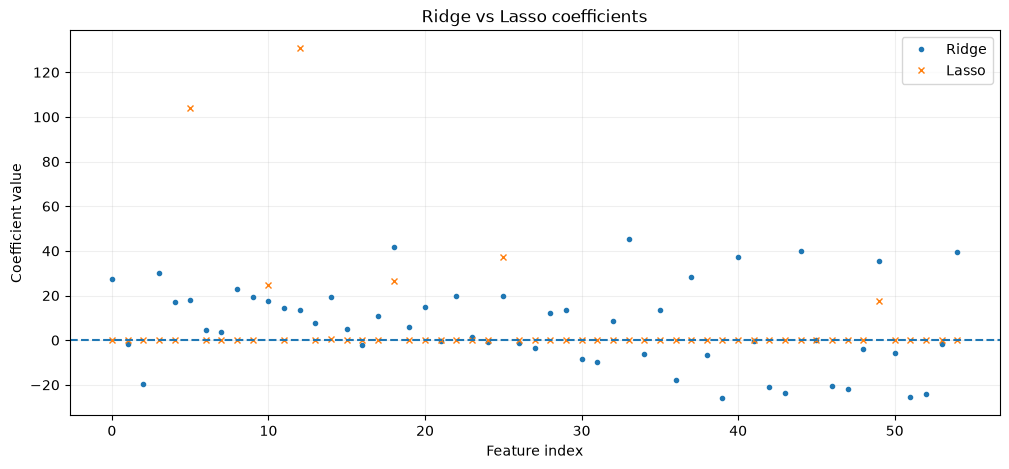

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    ridge_compare.coef_,
    marker='o',
    markersize=3,
    linestyle='none',
    label='Ridge'
)

plt.plot(
    lasso_compare.coef_,
    marker='x',
    markersize=4,
    linestyle='none',
    label='Lasso'
)

plt.axhline(0, linestyle='--')
plt.xlabel('Feature index')
plt.ylabel('Coefficient value')
plt.title('Ridge vs Lasso coefficients')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 5단계. 학생 응용 실습

1단계의 `lasso_compare`에서 `alpha`를 `1`, `10`, `100`으로 바꿔 가며 1~3단계를 다시 실행하고, 훈련 R²·테스트 R²·계수가 0인 특성의 수를 비교해 보세요. 결과는 아래 선택 확장 실습의 표와 대조할 수 있습니다.

**실습 핵심**: 같은 데이터와 특성을 사용하더라도 규제 방식에 따라 모델이 학습하는 계수는 달라집니다. 릿지는 계수의 크기를 전반적으로 제한하고, 라쏘는 일부 계수를 정확히 0으로 만들 수 있습니다. 하지만 계수가 작거나 0인 특성이 많다고 반드시 좋은 모델이 되는 것은 아닙니다.

✅ **완료 확인**: 2단계에서 릿지 `0.9904 / 0.9828`, 라쏘 `0.9888 / 0.9830`이 출력되고 규제 없는 선형 회귀의 테스트 R²는 큰 음수입니다. 3단계에서 릿지의 0인 계수는 `0`개, 라쏘는 `48`개이며, 규제 없는 선형 회귀의 계수 L2 크기는 릿지(약 146)·라쏘(약 176)와 자릿수부터 다릅니다.

## ⏩ 선택 확장 실습 — 라쏘의 alpha와 0인 계수 수 비교하기

`alpha`가 증가할수록 0인 계수의 수와 테스트 R²가 어떻게 달라지는지 확인합니다.

In [14]:
for alpha in [0.1, 1, 10, 100]:
    model = Lasso(
        alpha=alpha,
        max_iter=10000
    )

    model.fit(train_scaled, train_target)

    zero_count = np.sum(model.coef_ == 0)
    test_r2 = model.score(test_scaled, test_target)

    print(
        f'alpha={alpha:5.1f} | '
        f'0인 계수={zero_count:2d}개 | '
        f'테스트 R²={test_r2:.4f}'
    )

alpha=  0.1 | 0인 계수=42개 | 테스트 R²=0.9824
alpha=  1.0 | 0인 계수=47개 | 테스트 R²=0.9802
alpha= 10.0 | 0인 계수=48개 | 테스트 R²=0.9830
alpha=100.0 | 0인 계수=52개 | 테스트 R²=0.9091


`alpha`를 증가시키면 0인 계수가 전반적으로 많아지지만, `alpha=100`에서는 테스트 성능이 크게 낮아집니다. 규제를 강하게 하여 계수를 많이 제거하는 것이 항상 예측 성능 향상으로 이어지는 것은 아닙니다.

✅ **완료 확인**: 0인 계수가 `42 → 47 → 48 → 52`개로 늘고, 테스트 R²는 `0.9824 → 0.9802 → 0.9830 → 0.9091`로 `alpha=100`에서 크게 떨어집니다.